# Rotary Pendulum

In [1]:
import numpy as np
import control as ct
from numpy import sin, cos
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from functools import partial
import mediapy as media
import os
from scipy.linalg import solve_continuous_are
from scipy.optimize import minimize
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

from IPython.display import HTML, clear_output
clear_output()

pio.templates.default = "none"

# %matplotlib widget

In [2]:
mm = 1e-3                   # millimeters to meters
cm = 1e-2                   # centimeters to meters
grams = 1e-3                # grams to kilograms
DEGREES = np.pi / 180.0     # degrees to radians

## System Variables

| Variable | Value | Unit |
| --- | --- | --- |
| Arm Lenth | 140 | mm |
| Arm mass | 112.73 | g |
| Pendulum Length | 144 | mm |
| Pendulum mass | 36.58 | g |
| Motor Speed | 17.55 | rad/s |


In [3]:
L0 = 140*mm             # length of arm (m)
m0 = 112.72*grams       # mass of arm (kg)
L1 = 144*mm             # length of pendulum (m)
m1 = 36.58*grams        # mass of pendulum (kg)
l1 = L1/2              # distance from pivot to center of mass of pendulum (m)
g = 9.81                # acceleration due to gravity (m/s^2)

J0 = (1/3)*(L0**2)*m0   # moment of inertia of arm about pivot
J1 = (1/3)*(L1**2)*m1   # moment of inertia of pendulum

c0 = 1.3e-2             # friction coefficient of arm/motor
c1 = 4.3e-4             # friction coefficient of pendulum/pivot

In [4]:
# max_torque = 0.1765197 # N-m (1800 g·cm)
# max_torque = 0.2451663 # N-m (2500 g·cm)
max_torque = 50.0 # N-m (made up)
max_velocity = 17.55 # 2.9  # rad/s
T_motor = 0.05902 # 0.07232  # Approximately the time constant of the motor for a step response
# max_torque = 0.2  # maximum torque (N*m)  Load torque(g·cm): 1800-2500

## Control

### State Matricies

To get the Equations of Motion (EoM), lets get use the manipulator EoM:
$$
\mathbf{\tau} = \mathbf{M}(\mathbf{q})\mathbf{\ddot{q}} + \mathbf{C}(\mathbf{q}, \mathbf{\dot{q}})\mathbf{\dot{q}} + \mathbf{G}(\mathbf{q})
$$

Where:
- $\mathbf{\tau}$ = Applied torque
- $\mathbf{M}$ = Inertia
- $\mathbf{C}$ = Coriolis & Centripetal
- $\mathbf{g}$ = Gravity
- $\mathbf{q, \dot{q}, \ddot{q}}$ = Position, Velocity, Acceleration

For our problem, lets call the angle associated with the motor $\theta_0$ and the pendulum angle $\theta_1$. Therefore, 
$$
\mathbf{q} = 
\begin{bmatrix}
\theta_0 \\
\theta_1
\end{bmatrix}, 

\mathbf{\dot{q}} = 
\begin{bmatrix}
\dot{\theta_0} \\
\dot{\theta_1}
\end{bmatrix}, 

\mathbf{\ddot{q}} = 
\begin{bmatrix}
\ddot{\theta_0} \\
\ddot{\theta_1}
\end{bmatrix}.
$$

We can derive that (derivation on my github):
$$
\mathbf{M} = 
\begin{bmatrix}
J_0 + m_1  L_0^2 + m_1   l_1^2 \sin^2(\theta_1) & m_1  L_0  l_1  \cos(\theta_1)\\
m_1  L_0  l_1  \cos(\theta_1) & J_1 + m_1  l_1^2 
\end{bmatrix}
$$
<!-- $$
= 
\begin{bmatrix}
\alpha_1 + \alpha_4  \sin^2(\theta_1) & \alpha_3  \cos(\theta_1)\\
\alpha_3  \cos(\theta_1) & \alpha_2
\end{bmatrix},
$$ -->

$$
\mathbf{C} = 
\begin{bmatrix}
 m_1  l_1^2  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_1} + c_0 & m_1  l_1^2  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_0} -m_1  L_0  l_1  \sin(\theta_1)  \dot{\theta_1}\\
-m_1  l_1^2  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_1} & c_1
\end{bmatrix}
$$
<!-- $$
= 
\begin{bmatrix}
 \alpha_4  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_1} + c_0 & \alpha_4  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_0} -\alpha_3  \sin(\theta_1)  \dot{\theta_1}\\
-\alpha_4  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_1} & c_1
\end{bmatrix},
$$ -->

$$
\mathbf{G} = 
\begin{bmatrix}
0 \\
-m_1  l_1  g  \sin(\theta_1)
\end{bmatrix}
$$
<!-- $$
= 
\begin{bmatrix}
0 \\
\alpha_5  \sin(\theta_1)
\end{bmatrix},
$$ -->

$$
\mathbf{\tau} = 
\begin{bmatrix}
\tau_0\\
0
\end{bmatrix}
$$

Lets simplify the manipulator equation by using the following values:
$$
\alpha_1=J_0+m_1*L_0^{2}
$$

$$
\alpha_2=J_1+m_1*l_1^{2}
$$

$$
\alpha_3=m_1*L_0*l_1
$$

$$
\alpha_4=m_1*l_1^{2}
$$

$$
\alpha_5=-m_1  l_1  g 
$$


$$
\mathbf{M} = 
\begin{bmatrix}
\alpha_1 + \alpha_4  \sin^2(\theta_1) & \alpha_3  \cos(\theta_1)\\
\alpha_3  \cos(\theta_1) & \alpha_2
\end{bmatrix},
$$
$$
\mathbf{C} = 
\begin{bmatrix}
 \alpha_4  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_1} + c_0 & \alpha_4  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_0} -\alpha_3  \sin(\theta_1)  \dot{\theta_1}\\
-\alpha_4  \sin(\theta_1)  \cos(\theta_1)  \dot{\theta_1} & c_1
\end{bmatrix},
$$
$$
\mathbf{G} = 
\begin{bmatrix}
0 \\
\alpha_5  \sin(\theta_1)
\end{bmatrix},
$$

In [5]:
a1 = J0 + m1 * (L0**2)  # alpha 1
a2 = J1 + m1 * (l1**2)  # alpha 2
a3 = m1 * L0 * l1       # alpha 3
a4 = m1 * (l1**2)       # alpha 4
a5 = -m1 * l1 * g       # alpha 5

Linearizing it, we get:

$$
\mathbf{M} = 
\begin{bmatrix}
\alpha_1 &  \alpha_3\\
\alpha_3 & \alpha_2
\end{bmatrix}
$$

$$  
\mathbf{C} = 
\begin{bmatrix}
c_0 &  0\\
0 &  c_1
\end{bmatrix}
$$

$$
\mathbf{G} = 
\begin{bmatrix}
0\\
\alpha_5
\end{bmatrix}
$$

In [6]:
class FurutaPendulum:
    # def __init__(self, I0, L0, I1, l1, L1, m1, g = 9.81, c0=0.0, c1=0.0, initial_state=[0.0, 0.0, 0.0, 0.0]):

    def __init__(self, a1=a1, a2=a2, a3=a3, a4=a4, a5=a5, g=9.81, c0=c0, c1=c1, initial_state=[0.0, 0.0, 0.0, 0.0]):
        # Initial state = [theta0, theta1, theta0_dot, theta1_dot]
        
        self.a1 = a1
        self.a2 = a2
        self.a3 = a3
        self.a4 = a4
        self.a5 = a5

        self.g = g
        self.c0 = c0
        self.c1 = c1

        self.initial_state = np.array(initial_state)
        
        self.M = None
        self.C = None
        self.G = None

        self.q_ddot = np.zeros((2,1))
        
        self.reset()

    def reset(self):
        self.theta0, self.theta1, self.theta0_dot, self.theta1_dot = self.initial_state

        self.q = np.array([[self.theta0], 
                           [self.theta1]])
        
        self.q_dot = np.array([[self.theta0_dot], 
                               [self.theta1_dot]])
    
    
    def udpate_manipulator_EoM(self, tau=0.0):        

        self.M = np.array([[self.a1 + self.a4 * sin(self.theta1)**2,  self.a3 * cos(self.theta1)],
                           [self.a3 * cos(self.theta1), self.a2]])
        
        self.C = np.array([[self.a4 * sin(self.theta1) * cos(self.theta1) * self.theta1_dot + self.c0, self.a4 * sin(self.theta1) * cos(self.theta1) * self.theta0_dot - self.a3 * sin(self.theta1) * self.theta1_dot],
                           [-self.a4 * sin(self.theta1) * cos(self.theta1) * self.theta0_dot, self.c1]])
        
        self.G = np.array([[             0            ],
                           [self.a5 * sin(self.theta1)]])
        
        V = np.array([[tau], 
                      [0]])
        
        self.q = np.array([[self.theta0], 
                           [self.theta1]])
        
        self.q_dot = np.array([[self.theta0_dot], 
                               [self.theta1_dot]])
        
        self.q_ddot = np.linalg.solve(self.M, V - self.C @ self.q_dot - self.G)
    
    def step(self, t, state, tau_func=lambda t, state: 0.0):
        self.theta0, self.theta1, self.theta0_dot, self.theta1_dot = state
        
        tau = tau_func(t, state)
        self.udpate_manipulator_EoM(tau)
        return [self.theta0_dot, self.theta1_dot, self.q_ddot[0,0], self.q_ddot[1,0]]

In [7]:
initial_state=[0.0, 1*DEGREES, 0.0, 0.0]

pend = FurutaPendulum(a1=a1, 
                      a2=a2, 
                      a3=a3, 
                      a4=a4, 
                      a5=a5, 
                      g=g, 
                      c0=c0, 
                      c1=c1, 
                      initial_state=initial_state)

t_span = (0, 8)  # seconds


In [8]:
pend_obj = pend
pend_obj.reset()  # Reset to initial state before simulating with control

# Simulate
sol = solve_ivp(
    fun=lambda t, y: pend_obj.step(t, y),
    t_span=t_span,
    y0=initial_state,
    t_eval=np.linspace(t_span[0], t_span[1], 1000), 
    dense_output=True
)

print(f"Status: {sol.status}")
print(f"Message: {sol.message}")

Status: 0
Message: The solver successfully reached the end of the integration interval.


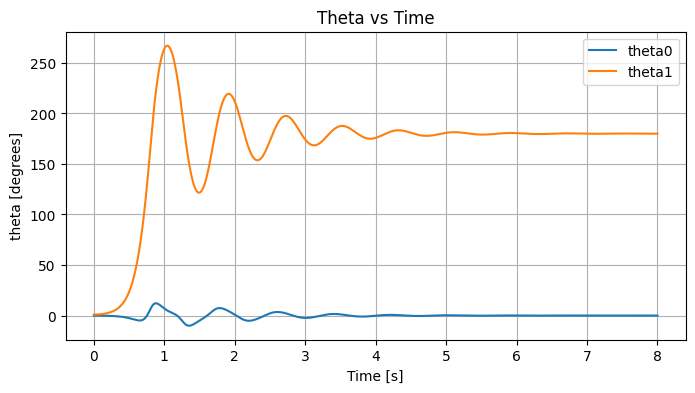

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(sol.t, sol.y[0]/DEGREES, label='theta0')
plt.plot(sol.t, sol.y[1]/DEGREES, label='theta1')
plt.xlabel('Time [s]')
plt.ylabel('theta [degrees]')
plt.title('Theta vs Time')
plt.grid(True)
plt.legend()
plt.show()

## Animate
Lets create a quick animation for the pendulum to make sure the EoM is good.

I am saving a video to a new folder "outputs". This might take a minute because it has to render each matplotlib plt frame.

If you run this in an actual python script, it is very fast to create a video. Just a long time to save it.

In [10]:
def update_animation(frame, states, L0=L0, L1=L1):
    # Pull from the resampled 'states' array instead of sol.y
    θ0 = states[0][frame]
    θ1 = states[1][frame]

    base = np.array([0, 0, 0])
    arm = np.array([L0 * np.cos(θ0), L0 * np.sin(θ0), 0])
    
    # ... Rotation logic ...
    R_z = [[np.cos(θ0), -np.sin(θ0), 0],
           [np.sin(θ0),  np.cos(θ0), 0],
           [0,           0,          1]]
    
    pend_pos_unrotated = np.array([0.0, L1 * np.sin(θ1), L1 * np.cos(θ1)])
    pend_pos = arm + np.dot(R_z, pend_pos_unrotated)

    line.set_data([base[0], arm[0], pend_pos[0]], 
                  [base[1], arm[1], pend_pos[1]])
    line.set_3d_properties([base[2], arm[2], pend_pos[2]])
    return line,

def plot_3d(zoom=1.0):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.set_xlim(-0.4, 0.4)
    ax.set_ylim(-0.4, 0.4)
    ax.set_zlim(-0.4, 0.2)
    return fig, ax

fps = 30
# Create time points separated by 1/fps seconds
t_eval = np.arange(t_span[0], t_span[1], 1/fps)

# sol.sol(t) evaluates the ODE solution at those specific moments
sol_resampled = sol.sol(t_eval) 

# 3D Animation
fig, ax = plot_3d(zoom=1.0)
line, = ax.plot([], [], [], 'o-', lw=2)

anim = FuncAnimation(
    fig, 
    partial(update_animation, states=sol_resampled, L0=L0, L1=L1), 
    frames=len(t_eval),     # Match the length of resampled time
    interval=1000/fps,      # For real-time playback in notebook
    blit=True
)

os.makedirs('outputs', exist_ok=True)

anim.save('outputs/plt_pendulum.mp4', 
          fps=fps,
          extra_args=[
              '-vcodec', 'libx264', 
              '-crf', '17',         # High quality (0-51, lower is better)
              '-g', '1',            # KEY: Keyframe every 1 frame (removes blur)
              '-pix_fmt', 'yuv420p' # Essential for browser compatibility
          ])

plt.close() # Prevents a duplicate static plot from appearing

In [11]:
plt_vid = media.read_video('outputs/plt_pendulum.mp4')
media.show_video(plt_vid, fps=fps)

This browser does not support the video tag.


## LQR Controller

Nice! We have a simple simulation for the furuta pendulum. Easier than creating a model in MuJoCo, right? Not really, but good news is, from the manipulator equation of motion, we can linearize about the equilibrium and design a controller to stabilize it there.

### What is LQR?

Quickly describe it and give links to the MIT website

In [12]:
# Linearized system matrices
M = np.array([[a1, a3], 
              [a3, a2]])
C = np.array([[c0, 0], 
              [0, c1]])
G = np.array([[0], 
              [a5]])
B_c = np.array([[1], 
                [0]])
dtau_dq = np.array([[0, 0], 
                   [0, a5]])
# For us, tau is zero at the equilibrium point, so we can ignore it for linearization purposes.

$$

\mathbf{x} = 
\begin{bmatrix}
\theta_0 \\
\theta_1 \\
\dot{\theta_0} \\
\dot{\theta_1}
\end{bmatrix},


\mathbf{\dot{x}} = 
\begin{bmatrix}
\dot{\theta_0} \\
\dot{\theta_1} \\
\ddot{\theta_0} \\
\ddot{\theta_1}
\end{bmatrix}
$$

In [13]:
z22 = np.zeros((2, 2))
A_bl = -np.linalg.inv(M) @ dtau_dq
A = np.block([[z22, np.eye(2)], 
              [A_bl, z22]])
A


array([[  0.        ,   0.        ,   1.        ,   0.        ],
       [  0.        ,   0.        ,   0.        ,   1.        ],
       [  0.        , -18.78576198,   0.        ,   0.        ],
       [  0.        ,  74.04765879,   0.        ,   0.        ]])

In [14]:
B = np.zeros((4, 1))
B[2:, :] = np.linalg.inv(M) @ B_c
B

array([[   0.        ],
       [   0.        ],
       [ 872.49883667],
       [-727.08236389]])

In [15]:
Q = np.diag([0.011, 0.04, 0.01, 0.025])    # Penalize θ heavily
# Q = np.diag([5, 0.1, 10, 0.1])    # Penalize θ heavily
R = np.array([[1]])     # Penalize force magnitude
P = solve_continuous_are(A, B, Q, R)
K = np.linalg.inv(R) @ B.T @ P  # LQR gain matrix
K

array([[-0.10488088, -2.61917121, -0.13242254, -0.37398474]])

In [16]:
# LQR controlled step with speed-torque limiting
def LQR_controlled_step(t, state, max_torque=None, max_velocity=max_velocity):
    state[0] = (state[0] + np.pi) % (2 * np.pi) - np.pi
    state[1] = (state[1] + np.pi) % (2 * np.pi) - np.pi
    
    theta0_dot = state[2]
    
    torque = (-K @ state)[0]
    
    # if max_torque is not None:
    #     torque = np.clip(torque, -max_torque, max_torque)
    if max_torque is not None:
        # Scale max torque down as velocity approaches max_velocity (Speed-Torque curve)
        speed_factor = max(0.0, 1.0 - (abs(theta0_dot) / max_velocity))
        current_max_torque = max_torque * speed_factor
        
        torque = np.clip(torque, -current_max_torque, current_max_torque)
        
    return torque

In [17]:
pend_obj = pend

pend_obj.reset()  # Reset to initial state before simulating with control

controller = partial(LQR_controlled_step, max_torque=max_torque)

sol = solve_ivp(
    fun=lambda t, state: pend_obj.step(t, state, tau_func=controller),
    t_span=t_span,
    y0=initial_state,
    t_eval=np.linspace(t_span[0], t_span[1], 1000),
    dense_output=True,
)

torques = [LQR_controlled_step(t, state, max_torque=max_torque) for t, state in zip(sol.t, sol.y.T)]

print(f"Status: {sol.status}")
print(f"Message: {sol.message}")

Status: 0
Message: The solver successfully reached the end of the integration interval.


In [18]:

fig = make_subplots(rows=2, cols=1, shared_xaxes=True)

fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[0] / DEGREES, name="theta0"),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[1] / DEGREES, name="theta1"),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(x=sol.t, y=torques, name="torque", line=dict(color="red")),
    row=2, col=1,
)

fig.update_layout(
    title="Theta and Control Torque vs Time",
    height=600,
    width=800,
)
fig.update_yaxes(title_text="theta [degrees]", row=1, col=1)
fig.update_yaxes(title_text="torque [N·m]", row=2, col=1)
fig.update_xaxes(title_text="Time [s]", row=2, col=1)

fig.show()

In [19]:
fps = 30
# Create time points separated by 1/fps seconds
t_eval = np.arange(t_span[0], t_span[1], 1/fps)

# sol.sol(t) evaluates the ODE solution at those specific moments
sol_resampled = sol.sol(t_eval) 

# 3D Animation
fig, ax = plot_3d(zoom=1.0)
line, = ax.plot([], [], [], 'o-', lw=2)

anim = FuncAnimation(
    fig, 
    partial(update_animation, states=sol_resampled, L0=L0, L1=L1), 
    frames=len(t_eval),     # Match the length of resampled time
    interval=1000/fps,      # For real-time playback in notebook
    blit=True
)

os.makedirs('outputs', exist_ok=True)

anim.save('outputs/plt_pendulum_LQR.mp4', 
          fps=fps, 
          extra_args=[
              '-vcodec', 'libx264', 
              '-crf', '17',        # High quality (0-51, lower is better)
              '-g', '1',           # KEY: Keyframe every 1 frame (removes blur)
              '-pix_fmt', 'yuv420p'# Essential for browser compatibility
          ])

plt.close() # Prevents a duplicate static plot from appearing

In [20]:
plt_vid = media.read_video('outputs/plt_pendulum_LQR.mp4')
media.show_video(plt_vid, fps=fps)

This browser does not support the video tag.


### Sweet!

Lets check out the solution for a more difficult initial conditions. Lets make the angle 2 degrees off and have some initial anguluar velocity for the pendulum.

In [21]:
initial_state=[-291.622*DEGREES, 2.2*DEGREES, 4.45, 1.7]

pend_diff = FurutaPendulum(a1=a1, 
                           a2=a2, 
                           a3=a3, 
                           a4=a4, 
                           a5=a5, 
                           g=g, 
                           c0=c0, 
                           c1=c1, 
                           initial_state=initial_state)

t_span = (0, 8)  # seconds


In [22]:
pend_obj = pend_diff

pend_obj.reset()  # Reset to initial state before simulating with control
    
sol = solve_ivp(
    fun=lambda t, state: pend_obj.step(t, state, tau_func=partial(LQR_controlled_step, max_torque=max_torque)), # partial(pend_obj.step, t, state, tau_func=lambda t, state:( -K @ state)[0])
    t_span=t_span,
    y0=initial_state,
    t_eval=np.linspace(t_span[0], t_span[1], 1000), 
    dense_output=True
)

torques = [LQR_controlled_step(t, state, max_torque=max_torque) for t, state in zip(sol.t, sol.y.T)]

print(f"Status: {sol.status}")
print(f"Message: {sol.message}")

Status: 0
Message: The solver successfully reached the end of the integration interval.


In [23]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True)

fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[0] / DEGREES, name="theta0"),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[1] / DEGREES, name="theta1"),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(x=sol.t, y=torques, name="torque", line=dict(color="red")),
    row=2, col=1,
)

fig.update_layout(
    title="Theta and Control Torque vs Time",
    height=600,
    width=800,
)
fig.update_yaxes(title_text="theta [degrees]", row=1, col=1)
fig.update_yaxes(title_text="torque [N·m]", row=2, col=1)
fig.update_xaxes(title_text="Time [s]", row=2, col=1)

fig.show()

In [24]:
fps = 30
# Create time points separated by 1/fps seconds
t_eval = np.arange(t_span[0], t_span[1], 1/fps)

# sol.sol(t) evaluates the ODE solution at those specific moments
sol_resampled = sol.sol(t_eval) 

# 3D Animation
fig, ax = plot_3d(zoom=1.0)
line, = ax.plot([], [], [], 'o-', lw=2)

anim = FuncAnimation(
    fig, 
    partial(update_animation, states=sol_resampled, L0=L0, L1=L1), 
    frames=len(t_eval),     # Match the length of resampled time
    interval=1000/fps,      # For real-time playback in notebook
    blit=True
)

os.makedirs('outputs', exist_ok=True) 

anim.save('outputs/plt_pendulum_diff_LQR.mp4', 
          fps=fps, 
          extra_args=[
              '-vcodec', 'libx264', 
              '-crf', '17',        # High quality (0-51, lower is better)
              '-g', '1',           # KEY: Keyframe every 1 frame (removes blur)
              '-pix_fmt', 'yuv420p'# Essential for browser compatibility
          ])

plt.close() # Prevents a duplicate static plot from appearing

In [25]:
plt_vid = media.read_video('outputs/plt_pendulum_diff_LQR.mp4')
media.show_video(plt_vid, fps=fps)

This browser does not support the video tag.


## Swing Up

We set up the problem such that the pendulum is straight down and there is no anguluar velocity

In [26]:
initial_state=[0.0, 180.0*DEGREES, 0.0, 0.0]

pend_su = FurutaPendulum(a1=a1, 
                         a2=a2, 
                         a3=a3, 
                         a4=a4, 
                         a5=a5, 
                         g=g, 
                         c0=c0, 
                         c1=c1, 
                         initial_state=initial_state)
pend_obj = pend_su


Using the feedforward bang-bang control that is described in Furuta's *Swing Up Control of Inverted Pendulum* paper

In [27]:
def bang_bang_control(t, state, T, max_torque=max_torque, max_velocity=max_velocity):
    
    # 1. Determine nominal time-based torque
    if t < T[0]:
        torque = -max_torque
    elif t < T[1]:
        torque = 0.0
    elif t < T[2]:
        torque = max_torque
    elif t < T[3]:
        torque = 0.0
    else:
        torque = 0.0  # End of sequence
        
    # 2. Enforce Back-EMF / Speed-Torque Droop Curve
    # Extract motor velocity (theta0_dot is index 2 in the state vector)
    theta0_dot = state[2]
    # Scale max torque down as velocity approaches max_velocity
    speed_factor = max(0.0, 1.0 - (abs(theta0_dot) / max_velocity))
    current_max_torque = max_torque * speed_factor
    
    # Clip the requested torque to the velocity-dependent limit
    torque = np.clip(torque, -current_max_torque, current_max_torque)
        
    return torque

Set up the simulation to end at T4 and return the states at T4

In [28]:
pend_obj = pend_su

def simulate_iteration(T, controller=bang_bang_control):
    # Setup
    t_span = (0, T[3])  # seconds
    pend_obj.reset()  # Reset to initial state before simulating with control

    sol = solve_ivp(
        fun=lambda t, state: pend_obj.step(t, state, tau_func=lambda t, s: controller(t, s, T=T, max_torque=max_torque)),
        t_span=t_span,
        y0=initial_state,
        t_eval=np.linspace(t_span[0], t_span[1], 1000),
        dense_output=True,
        method='RK45',
        atol=1e-8,
        rtol=1e-6 # Tighten tolerance for cleaner gradients
    )

    return sol.y[:, -1]  # Return the final state


Setting up the optimizer

In [29]:
Q_weight = np.diag([0.001, 20.0, 0.001, 5.0])    # Penalize θ0, θ1, θ0_dot, θ1_dot respectively

cons = [
    {'type': 'ineq', 'fun': lambda T: T[0]},              # T1 > 0
    {'type': 'ineq', 'fun': lambda T: T[1] - T[0]},       # T2 - T1 > 0
    # {'type': 'ineq', 'fun': lambda T: 2*T_motor - T[1]},   # T1 < 2*T_motor
    {'type': 'ineq', 'fun': lambda T: T[2] - T[1]},       # T3 - T2 > 0
    {'type': 'ineq', 'fun': lambda T: T[3] - T[2]},       # T4 - T3 > 0
    {'type': 'ineq', 'fun': lambda T:   3  - T[3]}        # T4 < 3 seconds (optional upper bound to prevent excessively long simulations)
]

def angle_distance_from_zero(angle):
    wrapped = (angle + np.pi) % (2 * np.pi) - np.pi
    return abs(wrapped)

def objective(T):
    final_state = simulate_iteration(T).copy()

    # Discontinuous if final state is pointing straight down (initial state)
    final_state[0] = angle_distance_from_zero(final_state[0])
    final_state[1] = angle_distance_from_zero(final_state[1])
    # final_state[0] = (final_state[0] + np.pi) % (2 * np.pi) - np.pi
    # final_state[1] = (final_state[1] + np.pi) % (2 * np.pi) - np.pi
    
    cropped_state = np.array([final_state[1],final_state[3]])
    cropped_Q = Q_weight[np.ix_([1, 3], [1, 3])]
    
    J = cropped_state.T @ cropped_Q @ cropped_state
    # J = final_state.T @ Q_weight @ final_state

    return J

Run the optimizer

In [30]:
# Initial guesses (used paper values)
T1_guess = T_motor
T2_guess = T1_guess+np.pi*np.sqrt(L1/(2*g))/2
T3_guess = T2_guess+T_motor
T4_guess = T3_guess+np.pi*np.sqrt(L1/(2*g))
initial_guess = np.array([T1_guess, T2_guess, T3_guess, T4_guess]) # Initial T1, T2, T3, T4
# initial_guess = np.array([0.06, 0.245, 0.355, 0.710]) # Initial T1, T2, T3, T4
# initial_guess = np.sort(np.random.uniform(0.0, 0.2, size=4))
print(f"Initial guess: {initial_guess}")


res = minimize(
    objective,
    initial_guess,
    method= "SLSQP", #'COBYLA', 'SLSQP', 'trust-constr'
    constraints=cons,
    options={
        'disp': True,
        'iprint': 2,    # 0: Silent, 1: Final summary, 2: Iteration details (Loss, Grad, etc.)
        'eps': 1e-3  # Increase epsilon for more stable numerical gradients
    }
)

print(f"Optimal Times (T1, T2, T3, T4): {res.x}")
print(f"Objective Value: {objective(res.x)}")

Initial guess: [0.05902    0.19359104 0.25261104 0.52175313]
  NIT    FC           OBJFUN            GNORM
    1     6     1.236114E+02     2.868391E+05
    2    20     1.173564E+03     3.431743E+05
    3    26     1.972849E+02     4.063190E+04
    4    34     8.363932E+02     2.437301E+03
    5    45     2.777308E+03     2.500483E+03
    6    52     2.093707E+02     6.083116E+03
    7    58     2.896220E+02     1.372594E+04
    8    65     6.414139E+02     1.824001E+04
    9    80     8.365839E+02     1.828181E+04
   10    95     1.971378E+02     1.829275E+04
   11   110     1.973921E+02     1.830028E+04
   12   125     5.497675E+02     1.828678E+04
   13   140     8.017090E+02     1.831878E+04
   14   155     2.690706E+02     1.832316E+04
   15   170     1.641008E+02     1.832409E+04
   17   185     1.921184E+02     1.836482E+04
   18   196     1.973921E+02     1.995870E+04
   19   211     1.973921E+02     1.990531E+04
   20   226     1.973921E+02     2.001523E+04
   21   241     4.8

Simulate the results from the optimization so we can see it

In [31]:
pend_obj = pend_su

pend_obj.reset()  # Reset to initial state before simulating with control

# Simulate
def controller(t, state):
    if t <= res.x[-1]:
        return bang_bang_control(
            t,
            state,
            T=res.x,
            max_torque=max_torque,
        )
    return 0.0  # Default torque when bang-bang sequence is over
    # return LQR_controlled_step(t, state, max_torque=max_torque, max_velocity=max_velocity)
    
sol = solve_ivp(
    fun=lambda t, state: pend_obj.step(t, state, tau_func=controller),
    t_span=t_span,
    y0=initial_state,
    t_eval=np.linspace(t_span[0], t_span[1], 1000), 
    dense_output=True,
    method='RK45',
    atol=1e-8,
    rtol=1e-6 # Tighten tolerance for cleaner gradients
)

torques = [controller(t, state) for t, state in zip(sol.t, sol.y.T)]

print(f"Status: {sol.status}")
print(f"Message: {sol.message}")

t_switch = res.x[-1]
idx = np.abs(sol.t - t_switch).argmin()

print(f"Target switch time: {t_switch:.6f} s")
print(f"Closest solution time: {sol.t[idx]:.6f} s")
print(f"State at switch: {sol.y[:, idx]}")
state = sol.y[:, idx]

print(f"theta0:     {state[0] / DEGREES:.3f} deg")
print(f"theta1:     {state[1] / DEGREES:.3f} deg")
print(f"theta0_dot: {state[2]:.3f} rad/s")
print(f"theta1_dot: {state[3]:.3f} rad/s")

cropped_state = np.array([angle_distance_from_zero(state[1]),state[3]])
cropped_Q = Q_weight[np.ix_([1, 3], [1, 3])]

print(f"Objective Function: {cropped_state.T @ cropped_Q @ cropped_state:.3f}")

Status: 0
Message: The solver successfully reached the end of the integration interval.
Target switch time: 0.394892 s
Closest solution time: 0.392392 s
State at switch: [-0.55998817 -0.14134975  3.21667505  0.01556284]
theta0:     -32.085 deg
theta1:     -8.099 deg
theta0_dot: 3.217 rad/s
theta1_dot: 0.016 rad/s
Objective Function: 0.401


In [32]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Dynamically extract the true global min/max for each row's data
# Row 1 data arrays
r1_data0 = sol.y / DEGREES
r1_data1 = sol.y / DEGREES
y1_min = min(np.min(r1_data0), np.min(r1_data1))
y1_max = max(np.max(r1_data0), np.max(r1_data1))
y1_bounds = [y1_min, y1_max]

# Row 2 data arrays
r2_data0 = sol.y
r2_data1 = sol.y
y2_min = min(np.min(r2_data0), np.min(r2_data1))
y2_max = max(np.max(r2_data0), np.max(r2_data1))
y2_bounds = [y2_min, y2_max]

# Row 3 data arrays
y3_bounds = [np.min(torques), np.max(torques)]


# 2. Build the Subplots
fig = make_subplots(rows=3, cols=1, shared_xaxes=True)

# Row 1 Traces
fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[0] / DEGREES, name="theta0"),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[1] / DEGREES, name="theta1"),
    row=1,
    col=1,
)

# --- Subplot 1 Vline Component ---
fig.add_trace(
    go.Scatter(
        x=[res.x[-1], res.x[-1]],
        y=y1_bounds,
        mode="lines",
        line=dict(color="green", dash="dash"),
        name="T4 (end of control)",
        legendgroup="T4_group",
        showlegend=True,
    ),
    row=1,
    col=1,
)

# Row 2 Traces
fig.add_trace(
    go.Scatter(
        x=sol.t, y=sol.y[2], name="theta0 dot", line=dict(dash="dot")
    ),
    row=2,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=sol.t, y=sol.y[3], name="theta1 dot", line=dict(dash="dot")
    ),
    row=2,
    col=1,
)

# --- Subplot 2 Vline Component ---
fig.add_trace(
    go.Scatter(
        x=[res.x[-1], res.x[-1]],
        y=y2_bounds,
        mode="lines",
        line=dict(color="green", dash="dash"),
        legendgroup="T4_group",
        showlegend=False,
    ),
    row=2,
    col=1,
)

# Row 3 Traces
fig.add_trace(
    go.Scatter(x=sol.t, y=torques, name="torque", line=dict(color="red")),
    row=3,
    col=1,
)

# --- Subplot 3 Vline Component ---
fig.add_trace(
    go.Scatter(
        x=[res.x[-1], res.x[-1]],
        y=y3_bounds,
        mode="lines",
        line=dict(color="green", dash="dash"),
        legendgroup="T4_group",
        showlegend=False,
    ),
    row=3,
    col=1,
)

# Layout & Axes Updates
fig.update_layout(
    title="Theta, Angular Velocity, and Control Torque vs Time",
    width=800,
    height=800,
)
fig.update_yaxes(title_text="theta [degrees]", showgrid=True, row=1, col=1)
fig.update_yaxes(title_text="theta dot [rad/s]", showgrid=True, row=2, col=1)
fig.update_yaxes(title_text="torque [N·m]", showgrid=True, row=3, col=1)
fig.update_xaxes(showgrid=True)
fig.update_xaxes(title_text="Time [s]", row=3, col=1)

fig.show()


In [33]:
fps = 30
# Create time points separated by 1/fps seconds
t_eval = np.arange(t_span[0], t_span[1], 1/fps)

# sol.sol(t) evaluates the ODE solution at those specific moments
sol_resampled = sol.sol(t_eval) 

# 3D Animation
fig, ax = plot_3d(zoom=1.0)
line, = ax.plot([], [], [], 'o-', lw=2)

anim = FuncAnimation(
    fig, 
    partial(update_animation, states=sol_resampled, L0=L0, L1=L1), 
    frames=len(t_eval),     # Match the length of resampled time
    interval=1000/fps,      # For real-time playback in notebook
    blit=True
)

os.makedirs('outputs', exist_ok=True)

anim.save('outputs/plt_pendulum_su.mp4', 
          fps=fps, 
          extra_args=[
              '-vcodec', 'libx264', 
              '-crf', '17',        # High quality (0-51, lower is better)
              '-g', '1',           # KEY: Keyframe every 1 frame (removes blur)
              '-pix_fmt', 'yuv420p'# Essential for browser compatibility
          ])

plt.close() # Prevents a duplicate static plot from appearing

In [34]:
plt_vid = media.read_video('outputs/plt_pendulum_su.mp4')
media.show_video(plt_vid, fps=fps)

This browser does not support the video tag.


## Tying it all together

In [35]:
pend_obj = pend_su

pend_obj.reset()  # Reset to initial state before simulating with control
# Simulate

def full_controller(t, state):
    if t <= res.x[-1]:
        return bang_bang_control(
            t,
            state,
            T=res.x,
            max_torque=max_torque,
        )
    # return 0.0  # Default torque when bang-bang sequence is over
    return LQR_controlled_step(t, state, max_torque=max_torque, max_velocity=max_velocity)
    
sol = solve_ivp(
    fun=lambda t, state: pend_obj.step(t, state, tau_func=full_controller),
    t_span=t_span,
    y0=initial_state,
    t_eval=np.linspace(t_span[0], t_span[1], 1000), 
    dense_output=True,
    method='RK45',
    atol=1e-8,
    rtol=1e-6 # Tighten tolerance for cleaner gradients
)

torques = [full_controller(t, state) for t, state in zip(sol.t, sol.y.T)]

print(f"Status: {sol.status}")
print(f"Message: {sol.message}")

Status: 0
Message: The solver successfully reached the end of the integration interval.


In [36]:
fig = make_subplots(rows=3, cols=1, shared_xaxes=True)

fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[0] / DEGREES, name="theta0"),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(x=sol.t, y=sol.y[1] / DEGREES, name="theta1"),
    row=1, col=1,
)
fig.add_vline(
    x=res.x[-1],
    line=dict(color="green", dash="dash"),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None], mode="lines",
        line=dict(color="green", dash="dash"),
        name="T4 (end of control)",
    ),
    row=1, col=1,
)

fig.add_trace(
    go.Scatter(
        x=sol.t, y=sol.y[2], name="theta0 dot",
        line=dict(dash="dot"),
    ),
    row=2, col=1,
)
fig.add_trace(
    go.Scatter(
        x=sol.t, y=sol.y[3], name="theta1 dot",
        line=dict(dash="dot"),
    ),
    row=2, col=1,
)

fig.add_trace(
    go.Scatter(
        x=sol.t, y=torques, name="torque",
        line=dict(color="red"),
    ),
    row=3, col=1,
)

fig.update_layout(
    title="Theta, Angular Velocity, and Control Torque vs Time",
    width=800,
    height=800,
)
fig.update_yaxes(title_text="theta [degrees]", showgrid=True, row=1, col=1)
fig.update_yaxes(title_text="theta dot [rad/s]", showgrid=True, row=2, col=1)
fig.update_yaxes(title_text="torque [N·m]", showgrid=True, row=3, col=1)
fig.update_xaxes(showgrid=True)
fig.update_xaxes(title_text="Time [s]", row=3, col=1)

fig.show()

In [37]:
fps = 30
# Create time points separated by 1/fps seconds
t_eval = np.arange(t_span[0], t_span[1], 1/fps)

# sol.sol(t) evaluates the ODE solution at those specific moments
sol_resampled = sol.sol(t_eval) 

# 3D Animation
fig, ax = plot_3d(zoom=1.0)
line, = ax.plot([], [], [], 'o-', lw=2)

anim = FuncAnimation(
    fig, 
    partial(update_animation, states=sol_resampled, L0=L0, L1=L1), 
    frames=len(t_eval),     # Match the length of resampled time
    interval=1000/fps,      # For real-time playback in notebook
    blit=True
)

os.makedirs('outputs', exist_ok=True)

anim.save('outputs/plt_pendulum_su_full.mp4', 
          fps=fps, 
          extra_args=[
              '-vcodec', 'libx264', 
              '-crf', '17',        # High quality (0-51, lower is better)
              '-g', '1',           # KEY: Keyframe every 1 frame (removes blur)
              '-pix_fmt', 'yuv420p'# Essential for browser compatibility
          ])

plt.close() # Prevents a duplicate static plot from appearing

In [38]:
plt_vid = media.read_video('outputs/plt_pendulum_su_full.mp4')
media.show_video(plt_vid, fps=fps)

This browser does not support the video tag.


In [39]:
print("Done")

Done
